### ============================================================
### House Prices Prediction
### ============================================================

Ziel dieses Projekts ist die vertiefte Analyse ausgewählter Modelle sowie deren Ensemble-Ansätze.

Das Projekt befindet sich derzeit noch in Bearbeitung und ist nicht vollständig abgeschlossen.

Der Fokus liegt auf dem systematischen Vergleich der Modelle, deren Evaluation sowie der Analyse der Modellleistung anhand geeigneter Metriken.

Gradient Boosting Models: LightGBM, CatBoost, XGBoost

    Business Context
Accurate house price estimation is a common regression task in real estate analytics.
Reliable predictions can support pricing strategies, investment decisions, and market analysis.

    Objective
Build and compare several gradient boosting models to predict house prices and evaluate them using cross-validation.

    Evaluation Metric
Root Mean Squared Error (RMSE) on a log-transformed target variable.

# 1️ Importing libraries / Importieren von Bibliotheken

In [14]:
# ===============================
# 1️ Importing libraries / Importieren von Bibliotheken
# ===============================
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor, Pool
import matplotlib.pyplot as plt
import seaborn as sns

# 2 Loading data / Daten laden

In [15]:
# ===============================
# 2 Loading data / Daten laden
# ===============================
train = pd.read_csv(r"..\data\raw\train.csv")  # у тебя train уже есть

# 3 Manual data preparation / Manuelle Datenaufbereitung

In [16]:
# ===============================
# 3 Manual data preparation / Manuelle Datenaufbereitung
# ===============================

# Target: applying logarithm for RMSE stability / Ziel: Logarithmus anwenden für stabile RMSE
y = np.log1p(train['SalePrice'])

# Features: removing target, Id, and duplicate log feature / Merkmale: Entfernen von Target, Id und doppeltem Log-Feature
X = train.drop(columns=['SalePrice', 'Id', 'SalePrice_log'], errors='ignore')

# Numerical and categorical features / Numerische und kategoriale Merkmale
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

print(f"Числовые признаки: {len(num_cols)}")
print(f"Категориальные признаки: {len(cat_cols)}")

# 3.1 Numerical features processing / 3.1 Verarbeitung numerischer Merkmale
X_num = X[num_cols].copy()
for col in X_num.columns:
    # Replacing NaN with median / Ersetzen von NaN durch Median
    X_num[col] = X_num[col].fillna(X_num[col].median())
    # Scaling (optional) / Skalierung (optional) масштабируем (опционально)
    X_num[col] = (X_num[col] - X_num[col].mean()) / X_num[col].std()

# 3.2 Categorical features processing / 3.2 Verarbeitung kategorialer Merkmale
X_cat = X[cat_cols].copy()
for col in X_cat.columns:
    # Replacing NaN with the most frequent value / Ersetzen von NaN durch den häufigsten Wert
    X_cat[col] = X_cat[col].fillna(X_cat[col].mode()[0])

# CatBoost can handle NaN directly, so we can leave them as is / CatBoost kann NaN direkt verarbeiten, daher können wir sie so belassen
# For LGBM and XGBoost, apply OneHotEncoding / Für LGBM und XGBoost OneHotEncoding anwenden
X_cat_ohe = pd.get_dummies(X_cat, drop_first=False)

# 3.3 Combining numerical and categorical features for LGBM/XGB / 3.3 Numerische und kategoriale Merkmale für LGBM/XGB zusammenführen
X_processed = pd.concat([X_num, X_cat_ohe], axis=1)

Числовые признаки: 36
Категориальные признаки: 43


C:\Users\UserS2025\AppData\Local\Temp\ipykernel_23576\1906416302.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns


# 4️ Cross-Validation for models / Kreuzvalidierung für Modelle

In [17]:
# ===============================
# 4️ Cross-Validation for models / Kreuzvalidierung für Modelle
# ===============================
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

# --- 4.1 LGBM ---
rmse_scores_lgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    lgb_model = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
    lgb_model.fit(X_train, y_train)
    y_pred = lgb_model.predict(X_val)
    rmse_scores_lgb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['LGBM'] = np.mean(rmse_scores_lgb)
print(f"LGBM: Average / Durchschnittlicher RMSE = {results['LGBM']:.4f}")

# --- 4.2 XGBoost ---
rmse_scores_xgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    xgb_model = XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
    xgb_model.fit(X_train, y_train)
    y_pred = xgb_model.predict(X_val)
    rmse_scores_xgb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['XGBoost'] = np.mean(rmse_scores_xgb)
print(f"XGBoost: Average / Durchschnittlicher RMSE = {results['XGBoost']:.4f}")

# --- 4.3 CatBoost ---
rmse_scores_cb = []
for train_idx, val_idx in kf.split(X):
    X_train, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # CatBoost: Replacing NaN in categorical features with "Missing" / Ersetzen von NaN in kategorialen Merkmalen durch "Missing"
    for col in cat_cols:
        X_train[col] = X_train[col].fillna("Missing")
        X_val[col] = X_val[col].fillna("Missing")

    cb_model = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
    cb_model.fit(X_train, y_train, cat_features=cat_cols.tolist())
    y_pred = cb_model.predict(X_val)
    rmse_scores_cb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['CatBoost'] = np.mean(rmse_scores_cb)
print(f"CatBoost: Average / Durchschnittlicher RMSE = {results['CatBoost']:.4f}")


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001325 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3202
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 178
[LightGBM] [Info] Start training from score 12.030658
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001087 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3203
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 181
[LightGBM] [Info] Start training from score 12.016898
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of 

# 6️ Feature Importance

In [18]:
# ===============================
# 6️ Feature Importance
# ===============================
# LGBM
lgb_model_final = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
lgb_model_final.fit(X_processed, y)
lgb_feat_imp = pd.DataFrame({
    'feature': X_processed.columns,
    'importance': lgb_model_final.feature_importances_
}).sort_values(by='importance', ascending=False)
print("Top-10 features / Top-10 Merkmale LGBM:")
print(lgb_feat_imp.head(10))

# CatBoost
X_cb_final = X.copy()
for col in cat_cols:
    X_cb_final[col] = X_cb_final[col].fillna("Missing")
cb_model_final = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
cb_model_final.fit(X_cb_final, y, cat_features=cat_cols.tolist())
cb_feat_imp = pd.DataFrame({
    'feature': X_cb_final.columns,
    'importance': cb_model_final.get_feature_importance()
}).sort_values(by='importance', ascending=False)
print("Top-10 features / Top-10 Merkmale CatBoost:")
print(cb_feat_imp.head(10))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002560 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3372
[LightGBM] [Info] Number of data points in the train set: 1460, number of used features: 187
[LightGBM] [Info] Start training from score 12.024057
Top-10 features / Top-10 Merkmale LGBM:
        feature  importance
15    GrLivArea        1187
2       LotArea         977
12     1stFlrSF         830
11  TotalBsmtSF         781
26   GarageArea         690
28  OpenPorchSF         674
10    BsmtUnfSF         639
7    MasVnrArea         570
8    BsmtFinSF1         568
1   LotFrontage         561
Top-10 features / Top-10 Merkmale CatBoost:
         feature  importance
45     GrLivArea   17.030963
16   OverallQual   16.876709
37   TotalBsmtSF    4.763418
18     YearBuilt    4.747397
52   KitchenQual    3.595896
33    BsmtF

# 7️ Hyperparameter Tuning (z.B.)

In [19]:
# ===============================
# 7️ Hyperparameter Tuning (z.B.)
# ===============================
# LGBM
lgb_grid = {
    'n_estimators': [500, 1000],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 50]
}
lgb_search = GridSearchCV(LGBMRegressor(random_state=42), lgb_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
lgb_search.fit(X_processed, y)
print("Best parameters / Beste Parameter LGBM:", lgb_search.best_params_)

# CatBoost
cb_model_tune = CatBoostRegressor(random_state=42, verbose=0)
cb_grid = {'depth': [4,6], 'learning_rate':[0.03,0.05], 'iterations':[500,1000]}
# GridSearchCV с CatBoost требует обёртку или кастомную функцию, для простоты можно пробовать вручную

# XGBoost
xgb_grid = {
    'n_estimators':[500,1000],
    'learning_rate':[0.05,0.1],
    'max_depth':[3,5]
}
xgb_search = GridSearchCV(XGBRegressor(random_state=42, verbosity=0), xgb_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
xgb_search.fit(X_processed, y)
print("Best parameters / Beste Parameter XGBoost:", xgb_search.best_params_)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002556 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3372
[LightGBM] [Info] Number of data points in the train set: 1460, number of used features: 187
[LightGBM] [Info] Start training from score 12.024057
Best parameters / Beste Parameter LGBM: {'learning_rate': 0.05, 'n_estimators': 500, 'num_leaves': 31}
Best parameters / Beste Parameter XGBoost: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 1000}


# 9️ Ensemble. Final Kaggle-ready prediction set / Finaler Kaggle-bereiter Vorhersagesatz

In [20]:
# ===============================
# 9️  Ensemble. Final Kaggle-ready prediction set / Finaler Kaggle-bereiter Vorhersagesatz
# ===============================

import pandas as pd
import numpy as np
from catboost import Pool

# 9.0 test.csv
test = pd.read_csv(r"..\data\raw\test.csv")

lgb_preds = lgb_model_final.predict(X_processed)
cb_preds = cb_model_final.predict(X_cb_final)

xgb_model_final = XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
xgb_model_final.fit(X_processed, y)
xgb_preds = xgb_model_final.predict(X_processed)

# 9.1 Test set preprocessing for LGBM/XGBoost / Testdatensatz-Vorverarbeitung für LGBM/XGBoost
X_test_num = test[num_cols].copy()
for col in X_test_num.columns:
    # Using median and statistics from the training set / Verwendung von Median und Statistiken aus dem Trainingssatz
    X_test_num[col] = X_test_num[col].fillna(X_num[col].median())
    X_test_num[col] = (X_test_num[col] - X_num[col].mean()) / X_num[col].std()

X_test_cat = test[cat_cols].copy()
for col in X_test_cat.columns:
    X_test_cat[col] = X_test_cat[col].fillna(X_cat[col].mode()[0])

X_test_cat_ohe = pd.get_dummies(X_test_cat, drop_first=False)
X_test_processed = pd.concat([X_test_num, X_test_cat_ohe], axis=1)

# Aligning columns with the training set (if there are differences in OHE) / Spalten mit dem Trainingssatz angleichen (falls Unterschiede im OHE vorhanden sind)
X_test_processed = X_test_processed.reindex(columns=X_processed.columns, fill_value=0)

# 9.2 Test set preprocessing for CatBoost / Testdatensatz-Vorverarbeitung für CatBoost
X_test_cb = test.copy()
for col in cat_cols:
    X_test_cb[col] = X_test_cb[col].astype(str).fillna("Missing")

# Creating a Pool for CatBoost to handle categorical features correctly / Erstellen eines Pools für CatBoost, um kategoriale Merkmale korrekt zu verarbeiten
test_pool = Pool(data=X_test_cb, cat_features=cat_cols.tolist())

# --- 9.3 RMSE на тренировочном наборе для всех комбинаций
rmse_dict = {}

# Solo
rmse_dict['LGBM'] = np.sqrt(mean_squared_error(y, lgb_preds))
rmse_dict['CatBoost'] = np.sqrt(mean_squared_error(y, cb_preds))
rmse_dict['XGBoost'] = np.sqrt(mean_squared_error(y, xgb_preds))

# Duet
rmse_dict['LGBM+CatBoost'] = np.sqrt(mean_squared_error(y, (lgb_preds + cb_preds)/2))
rmse_dict['LGBM+XGBoost'] = np.sqrt(mean_squared_error(y, (lgb_preds + xgb_preds)/2))
rmse_dict['CatBoost+XGBoost'] = np.sqrt(mean_squared_error(y, (cb_preds + xgb_preds)/2))

# Trio
rmse_dict['LGBM+CatBoost+XGBoost'] = np.sqrt(mean_squared_error(y, (lgb_preds + cb_preds + xgb_preds)/3))

print("✅ RMSE всех комбинаций на тренировке:")
for combo, rmse in rmse_dict.items():
    print(f"{combo}: {rmse:.4f}")

# --- 9.4 Взвешенный ансамбль для Kaggle
# На тренировке XGBoost лучше всех, поэтому даем ему больший вес
final_preds_log = (
    0.6 * xgb_model_final.predict(X_test_processed) +
    0.3 * lgb_model_final.predict(X_test_processed) +
    0.1 * cb_model_final.predict(test_pool)
)

# обратная трансформация log1p
final_preds = np.expm1(final_preds_log)

# --- 9.5 Создание CSV для Kaggle
test_ids = test['Id'] if 'Id' in test.columns else test.index
submission = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': final_preds
})
submission.to_csv('submission_kaggle.csv', index=False)
print("Файл 'submission_kaggle.csv' успешно создан!")

'''   Особенности этого кода:
Логарифмируем таргет для стабильного RMSE.
CatBoost работает с категориальными признаками напрямую.
LGBM/XGBoost используют OHE для категориальных.
Включён hyperparameter tuning (GridSearchCV) для LGBM и XGBoost.
Есть два варианта ансамбля: LGBM+CatBoost и LGBM+CatBoost+XGBoost.
Feature importance для LGBM и CatBoost.
Готов к применению на Kaggle. '''

✅ RMSE всех комбинаций на тренировке:
LGBM: 0.0192
CatBoost: 0.0807
XGBoost: 0.0153
LGBM+CatBoost: 0.0471
LGBM+XGBoost: 0.0154
CatBoost+XGBoost: 0.0456
LGBM+CatBoost+XGBoost: 0.0350
Файл 'submission_kaggle.csv' успешно создан!


'   Особенности этого кода:\nЛогарифмируем таргет для стабильного RMSE.\nCatBoost работает с категориальными признаками напрямую.\nLGBM/XGBoost используют OHE для категориальных.\nВключён hyperparameter tuning (GridSearchCV) для LGBM и XGBoost.\nЕсть два варианта ансамбля: LGBM+CatBoost и LGBM+CatBoost+XGBoost.\nFeature importance для LGBM и CatBoost.\nГотов к применению на Kaggle. '

### 9.7 Визуализация RMSE всех комбинаций

C:\Users\UserS2025\AppData\Local\Temp\ipykernel_23576\15543044.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='RMSE', y='Model', data=rmse_df, palette='viridis')


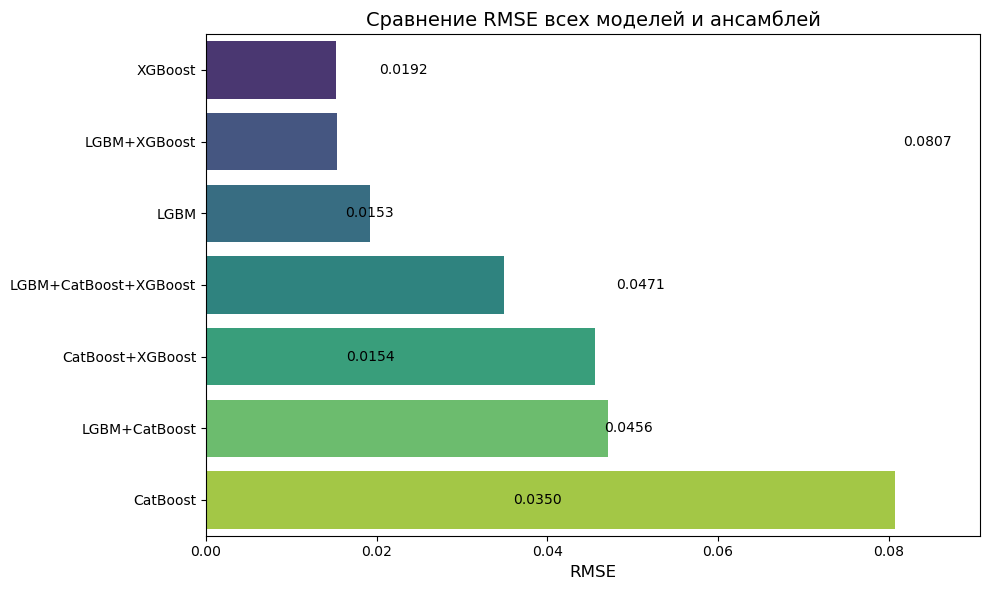

In [21]:
# ===============================
# 🔹 9.7 Визуализация RMSE всех комбинаций
# ===============================
import matplotlib.pyplot as plt
import seaborn as sns

# Преобразуем rmse_dict в DataFrame для графика
rmse_df = pd.DataFrame(list(rmse_dict.items()), columns=['Model', 'RMSE'])
rmse_df = rmse_df.sort_values('RMSE')

plt.figure(figsize=(10,6))
sns.barplot(x='RMSE', y='Model', data=rmse_df, palette='viridis')
plt.title('Сравнение RMSE всех моделей и ансамблей', fontsize=14)
plt.xlabel('RMSE', fontsize=12)
plt.ylabel('')
plt.xlim(0, rmse_df['RMSE'].max() + 0.01)
for index, row in rmse_df.iterrows():
    plt.text(row['RMSE'] + 0.001, index, f"{row['RMSE']:.4f}", va='center')
plt.tight_layout()
plt.show()


C:\Users\UserS2025\AppData\Local\Temp\ipykernel_23576\2531177073.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(rmse_dict.values()), y=list(rmse_dict.keys()), palette='viridis')


✅ RMSE всех комбинаций на тренировке:
LGBM: 0.0192
CatBoost: 0.0807
XGBoost: 0.0153
LGBM+CatBoost: 0.0471
LGBM+XGBoost: 0.0154
CatBoost+XGBoost: 0.0456
LGBM+CatBoost+XGBoost (simple): 0.0350
Weighted XGB:0.6 LGBM:0.3 CB:0.1: 0.0199
Weighted XGB:0.5 LGBM:0.3 CB:0.2: 0.0261
Weighted XGB:0.5 LGBM:0.4 CB:0.1: 0.0202


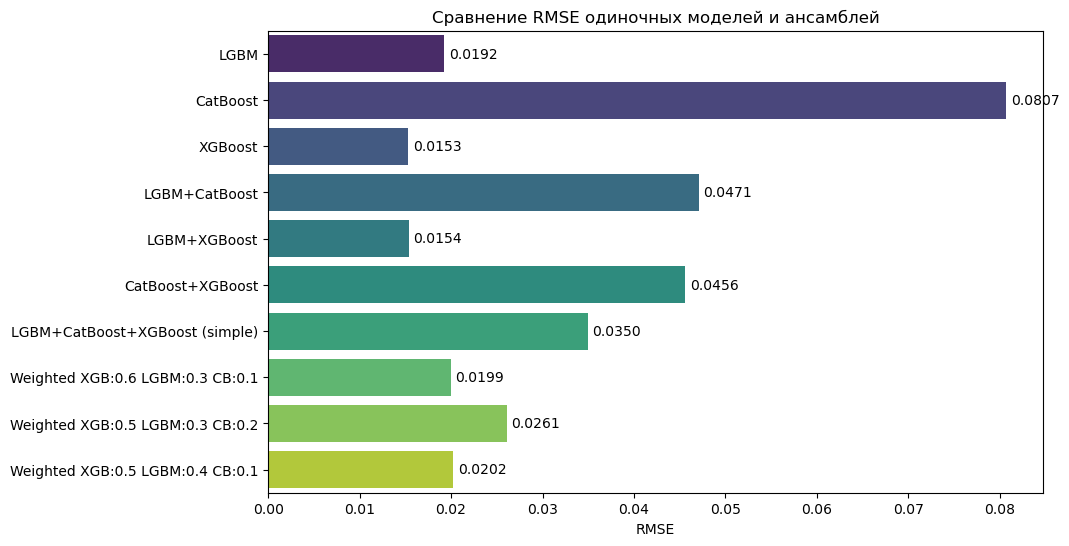

In [22]:
# ===============================
# 🔹 Сравнение RMSE всех комбинаций и веса ансамбля
# ===============================
'''
Строит красивый график, чтобы сразу видеть разницу.
Compares the RMSE of all in ... / Сравнивает RMSE всех одиночных моделей и ансамблей на тренировочном наборе.
Shows the effect of weighting in the ensemble./ Показывает влияние взвешивания на ансамбль. 
Plots a clear chart to immediately see the differences. / график , чтобы сразу видеть разницу.
-----
Shows which combination actually reduces the RMSE.
Allows visualizing how weighting XGBoost helps lower the error, while LGBM and CatBoost provide stability.
Enables easily adjusting the weights and immediately seeing the effect.
Показывает, какая комбинация реально снижает RMSE.
Позволяет визуально увидеть, как взвешивание XGBoost помогает снизить ошибку, при этом LGBM и CatBoost дают стабильность.
Можно легко менять веса и сразу видеть результат.
'''

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- RMSE одиночных моделей и простых ансамблей на тренировке ---
rmse_dict = {
    'LGBM': np.sqrt(mean_squared_error(y, lgb_preds)),
    'CatBoost': np.sqrt(mean_squared_error(y, cb_preds)),
    'XGBoost': np.sqrt(mean_squared_error(y, xgb_preds)),
    'LGBM+CatBoost': np.sqrt(mean_squared_error(y, (lgb_preds + cb_preds)/2)),
    'LGBM+XGBoost': np.sqrt(mean_squared_error(y, (lgb_preds + xgb_preds)/2)),
    'CatBoost+XGBoost': np.sqrt(mean_squared_error(y, (cb_preds + xgb_preds)/2)),
    'LGBM+CatBoost+XGBoost (simple)': np.sqrt(mean_squared_error(y, (lgb_preds + cb_preds + xgb_preds)/3))
}

# --- RMSE для взвешенных ансамблей XGB 0.6, LGBM 0.3, CatBoost 0.1 ---
weights = [(0.6,0.3,0.1), (0.5,0.3,0.2), (0.5,0.4,0.1)]  # можно проверить разные варианты
for w in weights:
    weighted_preds = w[0]*xgb_preds + w[1]*lgb_preds + w[2]*cb_preds
    rmse_dict[f'Weighted XGB:{w[0]} LGBM:{w[1]} CB:{w[2]}'] = np.sqrt(mean_squared_error(y, weighted_preds))

# --- Вывод RMSE всех вариантов ---
print("✅ RMSE всех комбинаций на тренировке:")
for combo, rmse in rmse_dict.items():
    print(f"{combo}: {rmse:.4f}")

# --- График ---
plt.figure(figsize=(10,6))
sns.barplot(x=list(rmse_dict.values()), y=list(rmse_dict.keys()), palette='viridis')
plt.title('Сравнение RMSE одиночных моделей и ансамблей')
plt.xlabel('RMSE')
plt.ylabel('')
for i, val in enumerate(rmse_dict.values()):
    plt.text(val + 0.0005, i, f"{val:.4f}", va='center')
plt.show()
